# FG spread · Куди піде фронт пожежі за добу?

**Тип:** виміряно. **Навіщо:** Чи пояснюють вітер, рельєф і паливо просування фронту краще за рівномірне зростання.

Цей ноутбук повторює блок сторінки досліджень `web/science/#e` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('FG_spread'))

T5 · Поширення пожежі: які гекси згорять за наступні 24 і 48 годин.

Задача      пожежа триває; відомо, що згоріло до моменту t (детекції VIIRS, ~2 прольоти на добу).
            Для кожного ще не згорілого гекса H3 res 8 (~0,74 км²) у радіусі 12 км від згарища — чи згорить він до t+24 год / t+48 год.
Події       28 багатоденних пожеж Греції 2021–2025 (FIRMS VIIRS S-NPP, ST-DBSCAN 1,5 км / 2 доби, ≥ 80 детекцій, ≥ 3 доби з детекціями).
Ознаки      геометрія фронту (відстань до згарища й до активних детекцій за 24 год, частка згорілих сусідів), динаміка
            (площа, приріст і просування фронту за 24 год, вектор руху), вітер NASA POWER (погодинно: швидкість, напрямок → косинус
            кута між вітром і напрямком на гекс), рельєф SRTM (ухил від фронту до гекса), паливо Hansen (лісистість 2000, недавні втрати).
            Погода на наступну добу береться фактична — як заміна прогнозу погоди (в експлуатації — прогноз).
Протокол    Еврос-2023 — недоторканий тест (не бере участі н

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,approach,lofo_f1_24,lofo_f1_24_ci,test_f1_24,test_f1_48,champion
0,iso,0.195,0.156–0.232,0.201,0.212,False
1,motion,0.210,0.168–0.248,0.204,0.221,False
2,wind,0.210,0.170–0.252,0.179,0.182,False
3,logreg,0.238,0.207–0.270,0.290,0.328,False
4,lightgbm,0.284,0.253–0.313,0.304,0.338,False
5,lightgbm_lag,0.290,0.257–0.321,0.276,0.310,True


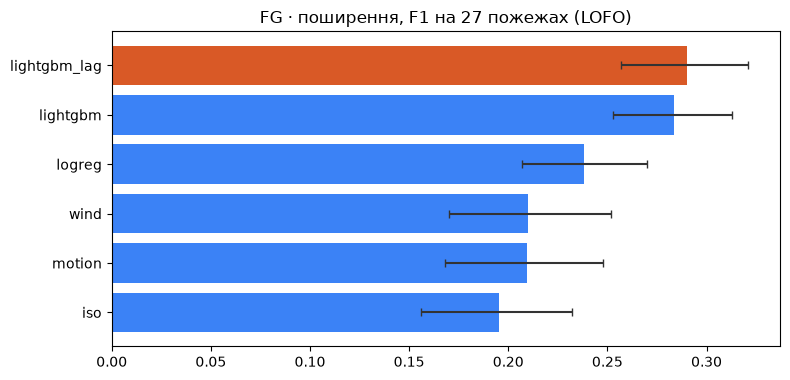

In [3]:
table, fig = report.show('FG_spread')
table